<a href="https://colab.research.google.com/github/TlameloPatlakwe/AI-for-S-E-Projects/blob/main/Assignment_6_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Hierarchical Clustering of Heterogeneous Slope Conditions using K-Means**

# Identify patterns in groundwater and lithology strength characteristics

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
from google.colab import files

In [9]:
uploaded = files.upload()
df = pd.read_excel(next(iter(uploaded)))
print("Dataset shape:", df.shape)
display(df.head())

Saving MAIN DATASET (1).xlsx to MAIN DATASET (1) (1).xlsx
Dataset shape: (197, 29)


,CASE,COMPRESSIVE STRENGTH(KIMBERLITE),mb,s,a,COMPRESSIVE STRENGTH(CS),mb.1,s.1,a.1,COMPRESSIVE STRENGTH(DOLOMITE),...,s.4,a.4,TENSILE STRENGTH(SAND),FRICTION ANGLE,COHESION,TENSILE STRENGTH(CALCRETE),FRICTION ANGLE.1,COHESION.1,RU,FoS
0,1,36064.238781,1.917204,0.004320,0.510723,119041.677640,0.530627,0.001319,0.526136,289562.638924,...,0.000819,0.502310,1,33.738229,1,1,29.868210,1,0.075,1.15
1,2,31972.366503,1.521989,0.003706,0.482796,159679.036671,0.536456,0.001330,0.530334,349270.527018,...,0.000677,0.521358,1,35.070238,1,1,31.408754,1,0.075,1.16
2,3,49284.275233,1.866600,0.003728,0.527070,112964.325185,0.546670,0.001301,0.498686,254765.340051,...,0.001190,0.497564,1,36.104115,1,1,30.813811,1,0.075,1.16
3,4,35688.098048,1.161285,0.004989,0.511970,134780.822237,0.493544,0.001742,0.498678,310609.492012,...,0.000905,0.509303,1,33.627620,1,1,29.443068,1,0.075,1.15
4,5,48537.055490,1.282094,0.003034,0.518658,125591.834894,0.498928,0.001702,0.490356,343384.475454,...,0.000723,0.493015,1,34.744877,1,1,28.520856,1,0.075,1.46


In [10]:
features = ['RU', 'FRICTION ANGLE.1', 'mb']
working = df[features + ['FoS']].dropna().copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(working[features])
print('Cases used:', len(working))

Cases used: 197


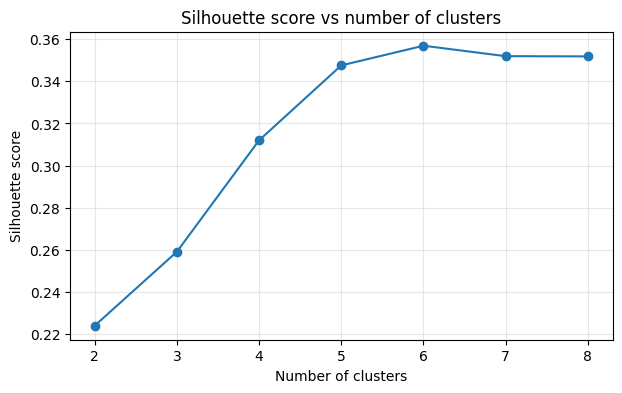

Best K within tested range: 6
 Clusters  Silhouette
        2       0.224
        3       0.259
        4       0.312
        5       0.348
        6       0.357
        7       0.352
        8       0.352


In [11]:
ks = list(range(2, 9))
scores = []
for k in ks:
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))
plt.figure(figsize=(7,4))
plt.plot(ks, scores, 'o-')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.title('Silhouette score vs number of clusters')
plt.grid(alpha=.3)
plt.show()
best_k = ks[int(np.argmax(scores))]
print('Best K within tested range:', best_k)
print(pd.DataFrame({'Clusters':ks,'Silhouette':scores}).round(3).to_string(index=False))

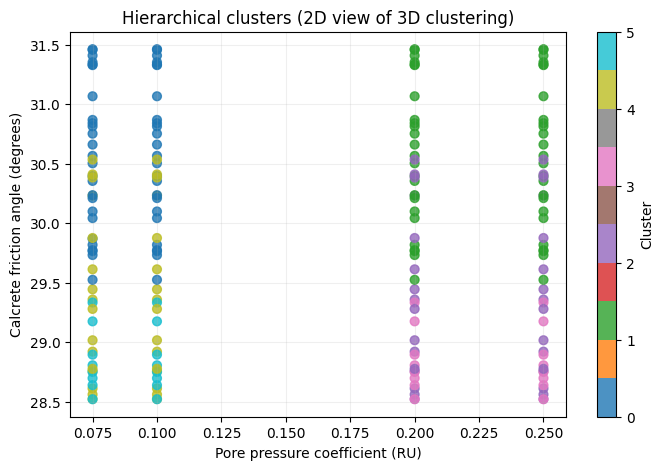

In [12]:
model = AgglomerativeClustering(n_clusters=best_k, linkage='ward')
working['Cluster'] = model.fit_predict(X_scaled)
plt.figure(figsize=(8,5))
scatter = plt.scatter(working['RU'], working['FRICTION ANGLE.1'], c=working['Cluster'], cmap='tab10', s=40, alpha=.8)
plt.xlabel('Pore pressure coefficient (RU)')
plt.ylabel('Calcrete friction angle (degrees)')
plt.title('Hierarchical clusters (2D view of 3D clustering)')
plt.colorbar(scatter, label='Cluster')
plt.grid(alpha=.2)
plt.show()

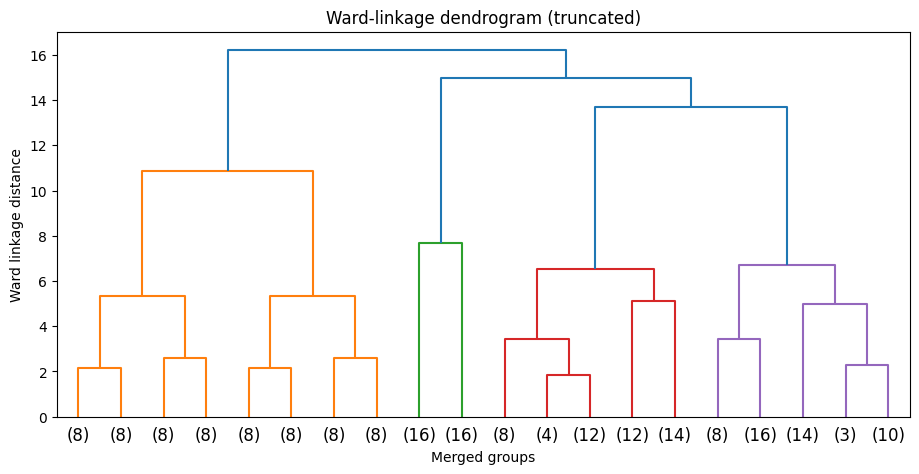

In [13]:
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(11,5))
dendrogram(Z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.title('Ward-linkage dendrogram (truncated)')
plt.xlabel('Merged groups')
plt.ylabel('Ward linkage distance')
plt.show()

,Cases,Mean_RU,Mean_Calcrete_Friction,Mean_Kimberlite_mb,Mean_FoS,Min_FoS,Max_FoS,Unstable_Share
Cluster,,,,,,,,
0,51,0.087,30.560,1.598,1.341,1.04,1.52,0.0
1,50,0.225,30.574,1.591,0.748,0.58,0.90,1.0
2,32,0.225,29.392,1.232,0.757,0.61,0.90,1.0
3,16,0.225,28.851,1.895,0.778,0.68,0.88,1.0
4,32,0.088,29.392,1.232,1.360,1.06,1.53,0.0
5,16,0.088,28.851,1.895,1.406,1.27,1.60,0.0


<Figure size 800x400 with 0 Axes>

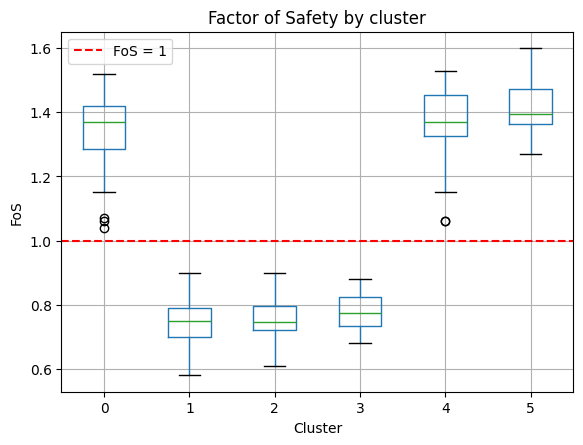

In [14]:
summary = working.groupby('Cluster').agg(
    Cases=('FoS','size'), Mean_RU=('RU','mean'),
    Mean_Calcrete_Friction=('FRICTION ANGLE.1','mean'),
    Mean_Kimberlite_mb=('mb','mean'),
    Mean_FoS=('FoS','mean'),
    Min_FoS=('FoS','min'), Max_FoS=('FoS','max'),
    Unstable_Share=('FoS', lambda s: (s < 1).mean())
)
display(summary.round(3))
plt.figure(figsize=(8,4))
working.boxplot(column='FoS', by='Cluster')
plt.title('Factor of Safety by cluster')
plt.suptitle('')
plt.ylabel('FoS')
plt.axhline(1, color='red', linestyle='--', label='FoS = 1')
plt.legend()
plt.show()

**Discussion**
Using standardized RU, friction angle(calcrete) and mb (kimberlite), Ward Linkage Hierarchical clustering identified six clusters.

Clusters 0,4 and 5 have low average RU(0.087-0.088) and higher average FoS(1.34-1.41). Clusters 1,2 and 3 have higher average RU (0.225) and lower average FoS (0.75-0.78).This suggests that groundwater conditions are strongly associated with the stability differences observed in these simulations.The clusters are not predefined stable/unstable labels and the associations do npt prove causation.
